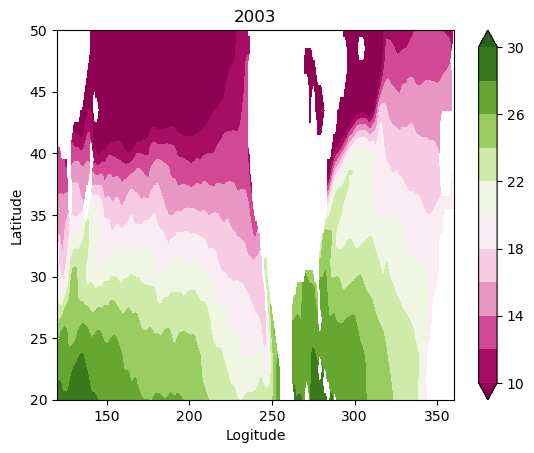

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

loadfile = 'sst_OISST.npz'
sst_dataset = np.load(loadfile)

sst = sst_dataset['sst']

lon2 = sst_dataset['lon2']

lat2 = sst_dataset['lat2']

y = sst_dataset['y']

m = sst_dataset['m']

#A 問題
# 20030509
draw_year = 2003
draw_month = 5

vmin = 10
vmax = 30
vint = 2

# pink-white-green
cm = plt.get_cmap('PiYG')

cs = plt.contourf(lon2, lat2, \
                  np.squeeze(sst[:, :, (y==draw_year)*(m==draw_month)]), \
                  cmap=cm, norm=Normalize(vmin=vmin, vmax=vmax), \
                  levels=np.arange(vmin,vmax+vint,vint), extend='both')

plt.colorbar(cs)
plt.xlabel('Logitude')
plt.ylabel('Latitude')
plt.xlim(120, 360)
plt.ylim(20, 50)

title = str(draw_year)
plt.title(title)

plt.show()

In [2]:
# B問題
# B-1
A = np.array([[1, 2, 4], 
             [4, 3, 5], 
             [6, 2, 9]])

B = np.array([5, 5, 4])

# B==4会判断数组B里面的元素是否等于4，不等于4返回false 等于返回true 
# 所以是false false true
print(B == 4)

# 前一部分由：来指定行，但是现在没有指定，后一部分由B==4来指定列
# 指定列的时候只保留为true的部分，对应B数组的第三列，所以对应提取A数组的第三列
print(A[:, B == 4])

# B-2
# 在年份y和draw year相等的时候为true，不相等的时候为false
# 月份也同理
# 两个true相乘才为true，其余的可能都是false，所以相乘为true的情况就等于年份和月份都为期望值的情况
# 最后可以指定一个经度和纬度任意，但是年份是指定值的平面

[False False  True]
[[4]
 [5]
 [9]]


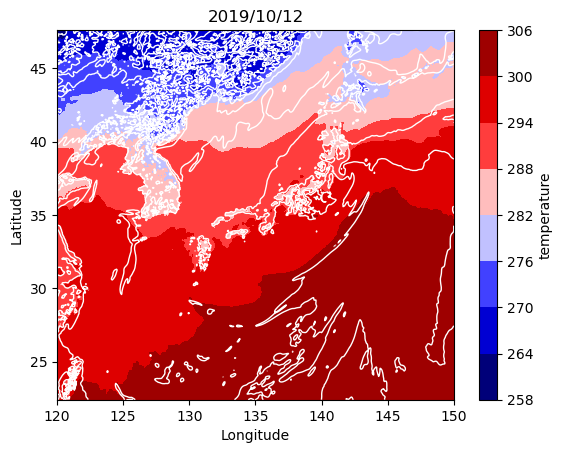

In [3]:
# c問題
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

draw_year = 2019
draw_month = 10
draw_day = 12
draw_hour = 18

loadfile = 'msm_20191012.npz'
msm_set = np.load(loadfile) # 读取文件

lon2 = msm_set['lon2']
lat2 = msm_set['lat2']
sp = msm_set['surface_pressure']
hour = msm_set['h']
t = msm_set['temperature']
h = msm_set['humidity']
r = msm_set['rain1h']
c = msm_set['cloud']

vmin = 0
vmax = 24
vint = 1

cm = plt.get_cmap('seismic')
t2d = np.squeeze(t[:, :, hour==draw_hour]) # 按照时间去切一个二位切片，实现数组降维
h2d = np.squeeze(h[:, :, hour==draw_hour])

draw_t = plt.contourf(lon2, lat2, t2d, cmap=cm) # contourf(X,Y,Z,cmap=..),XY是横坐标和纵坐标，z是对应坐标上的数值，cmap涂颜色
# 最后生成包含颜色映射的图形对象，存到draw_t里面
plt.colorbar(draw_t, label='temperature') #将生成的映像传进去，生成右边的色带

draw_h = plt.contour(lon2, lat2, h2d, colors='white', linewidths=1.0) #只绘制线条不填充颜色，意义如上

plt.xlabel('Longitude') #给坐标轴添加文字说明
plt.ylabel('Latitude')


title = str(draw_year) + '/' + str(draw_month) + '/' + str(draw_day)
plt.title(title)

plt.show()

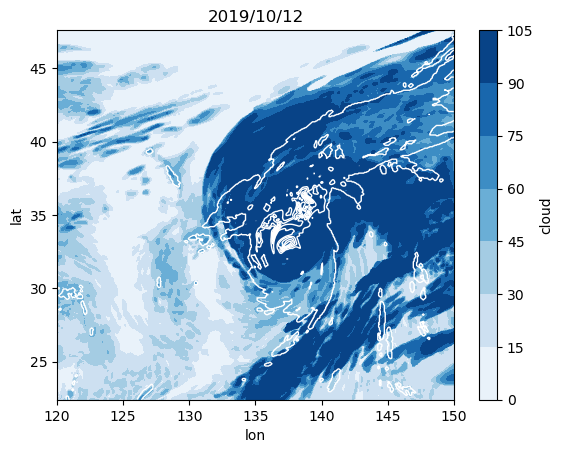

In [4]:
# c問題 もうひとつ図
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

loadfile = 'msm_20191012.npz'
msm_set = np.load(loadfile)

lon2 = msm_set['lon2']
lat2 = msm_set['lat2']
c = msm_set['cloud']
r = msm_set['rain1h']
h = msm_set['h']

draw_hour = 2

cm = plt.get_cmap('Blues')
c2d = np.squeeze(c[:, :, h==draw_hour])
r2d = np.squeeze(r[:, :, h==draw_hour])

draw_c = plt.contourf(lon2, lat2, c2d, cmap=cm)
plt.colorbar(draw_c, label='cloud')

draw_h = plt.contour(lon2, lat2, r2d, colors='white', linewidths=1.0)

plt.xlabel('lon')
plt.ylabel('lat')

title = '2019/10/12'
plt.title(title)

plt.show()


In [5]:
# D問題 将nc读取成npz形式保存
import numpy as np
import datetime
import netCDF4 as nc4
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize

loadfile = '0509.nc'
msm_data = nc4.Dataset(loadfile, 'r')

#!ncdump -h 0509.nc # 读取所有数据
surface_pressure = msm_data.variables['psea'][:]
surface_pressure = surface_pressure.transpose(2, 1, 0)
surface_pressure = surface_pressure.astype(float)

temperature = msm_data.variables['temp'][:]
temperature = temperature.transpose(2, 1, 0)
temperature = temperature.astype(float)

humidity = msm_data.variables['rh'][:]
humidity = humidity.transpose(2, 1, 0)
humidity = humidity.astype(float)

rain1h = msm_data.variables['r1h'][:]
rain1h = rain1h.transpose(2, 1, 0)
rain1h = rain1h.astype(float)

cloud = msm_data.variables['ncld_upper'][:]
cloud = cloud.transpose(2, 1, 0)
cloud = cloud.astype(float)

[imt, jmt, tmt] = temperature.shape
print([imt, jmt, tmt])

lon = msm_data.variables['lon'][:]
lat = msm_data.variables['lat'][:]
[xgrid2, ygrid2] = np.meshgrid(lon, lat)
lon2 = (xgrid2.T).astype(float)
lat2 = (ygrid2.T).astype(float)
del lon, lat
print([lon2, lat2])

y = np.zeros(tmt)
m = np.zeros(tmt)
d = np.zeros(tmt)
h = np.zeros(tmt)

date_offset = datetime.datetime(2003, 5, 9)
time = msm_data.variables['time'][:]
for tt in range(0, tmt):
    time_data = date_offset + datetime.timedelta(hours=int(time[tt]))
    y[tt] = time_data.year
    m[tt] = time_data.month
    d[tt] = time_data.day
    h[tt] = time_data.hour
print([y, m, d, h])

savefile = 'msm_20030509.npz'
np.savez(savefile, surface_pressure=surface_pressure, \
         temperature = temperature, humidity = humidity, \
         cloud = cloud, rain1h = rain1h, lon2 = lon2, lat2 = lat2, \
         y = y, m = m, d = d, h = h)

[240, 252, 24]
[masked_array(
  data=[[120.   , 120.   , 120.   , ..., 120.   , 120.   , 120.   ],
        [120.125, 120.125, 120.125, ..., 120.125, 120.125, 120.125],
        [120.25 , 120.25 , 120.25 , ..., 120.25 , 120.25 , 120.25 ],
        ...,
        [149.625, 149.625, 149.625, ..., 149.625, 149.625, 149.625],
        [149.75 , 149.75 , 149.75 , ..., 149.75 , 149.75 , 149.75 ],
        [149.875, 149.875, 149.875, ..., 149.875, 149.875, 149.875]],
  mask=False,
  fill_value=1e+20), masked_array(
  data=[[47.59999847, 47.5       , 47.40000153, ..., 22.70000076,
         22.60000038, 22.5       ],
        [47.59999847, 47.5       , 47.40000153, ..., 22.70000076,
         22.60000038, 22.5       ],
        [47.59999847, 47.5       , 47.40000153, ..., 22.70000076,
         22.60000038, 22.5       ],
        ...,
        [47.59999847, 47.5       , 47.40000153, ..., 22.70000076,
         22.60000038, 22.5       ],
        [47.59999847, 47.5       , 47.40000153, ..., 22.70000076,
      